<a href="https://colab.research.google.com/github/anacarolineferreira07/Inform-tica-Aplicada-a-Log-stica-/blob/main/Regress%C3%A3oLineardehoradeestudo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# URL do arquivo bruto (raw) do GitHub
url = 'https://raw.githubusercontent.com/Sainathmudigonda/Student-Result-Analysis/main/student_exam_scores.csv'

# Importando os dados para o DataFrame
df = pd.read_csv(url)

# Exibindo as primeiras linhas do DataFrame
display(df.head())

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Selecionando as variáveis explicativas (X) e a variável alvo (y)
# Vamos remover 'student_id' por ser apenas um identificador único
X = df[['hours_studied']]
y = df['exam_score']

# Dividindo os dados em 80% treino e 20% teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializando e treinando o modelo de regressão linear
model = LinearRegression()
model.fit(X_train, y_train)

# Fazendo previsões no conjunto de teste
y_pred = model.predict(X_test)

# Calculando métricas de avaliação
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Erro Quadrático Médio (MSE): {mse:.4f}")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")

Erro Quadrático Médio (MSE): 19.1626
Coeficiente de Determinação (R²): 0.6389


In [3]:
# Exibindo a importância (coeficientes) de cada variável no modelo
coef_df = pd.DataFrame({
    'Característica': X.columns,
    'Coeficiente': model.coef_
})

print("Intercepto do modelo (Constante):", model.intercept_)
display(coef_df)

Intercepto do modelo (Constante): -2.204963905836877


,Característica,Coeficiente
0,hours_studied,1.549341
1,sleep_hours,0.884156
2,attendance_percent,0.108949
3,previous_scores,0.183034


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


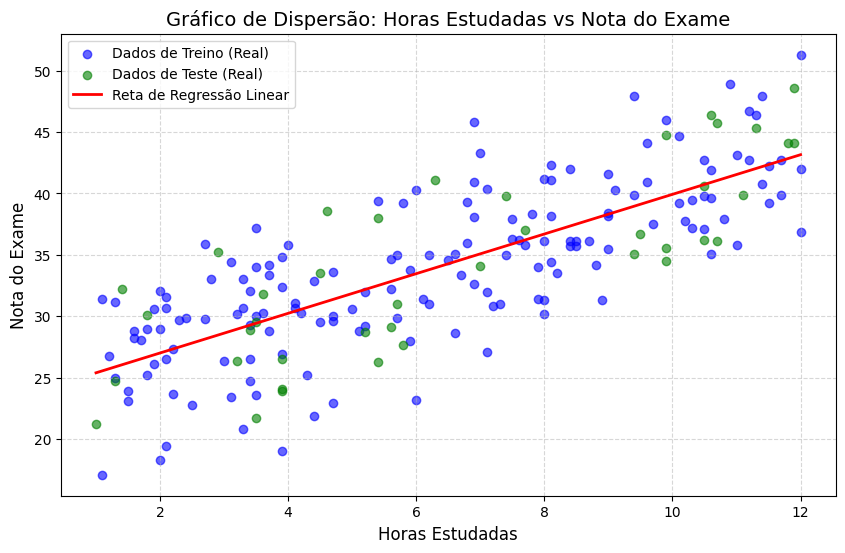

In [5]:
import matplotlib.pyplot as plt

# Criando a figura do gráfico
plt.figure(figsize=(10, 6))

# Gráfico de dispersão com os dados reais (Treino em azul, Teste em verde)
plt.scatter(X_train['hours_studied'], y_train, color='blue', alpha=0.6, label='Dados de Treino (Real)')
plt.scatter(X_test['hours_studied'], y_test, color='green', alpha=0.6, label='Dados de Teste (Real)')

# Criando pontos para desenhar a reta de regressão linear prevista pelo modelo
X_range = np.linspace(X['hours_studied'].min(), X['hours_studied'].max(), 100).reshape(-1, 1)
y_range_pred = model.predict(X_range)

# Desenhando a linha de regressão
plt.plot(X_range, y_range_pred, color='red', linewidth=2, label='Reta de Regressão Linear')

# Customizações do gráfico
plt.title('Gráfico de Dispersão: Horas Estudadas vs Nota do Exame', fontsize=14)
plt.xlabel('Horas Estudadas', fontsize=12)
plt.ylabel('Nota do Exame', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Exibindo o gráfico
plt.show()